## 프로젝트 1. 경사 하강법으로 이미지 복원하기

### 프로젝트 개요와 목표

이번 프로젝트에서 우리가 풀 문제는 다음과 같습니다.

이미지 처리를 위해 만들어 두었던 weird_function() 함수에 실수로 버그가 들어가 100×100 픽셀의 오염된 미미지가 만들어졌습니다. 이 오염된 이미지와 오염되기 전 원본 이미지를 동시에 파일로 저장하려고 했으나, 모종의 이유로 원본 이미지 파일은 삭제된 상황입니다. 다행히도 weird_function()의 소스코드는 남아 있습니다. 오염된 이미지와 weird_function()을 활용해 원본 이미지를 복원해봅시다.

*참고자료: https://github.com/jcjohnson/pytorch-examples, NYU Intro2ML*

In [4]:
import torch # 라이브러리 임포트
import pickle # 라이브러리 임포트
import matplotlib.pyplot as plt # 라이브러리 임포트

# 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'  # 변수 설정
plt.rcParams['axes.unicode_minus'] = False     # 변수 설정

shp_original_img = (100, 100) # 변수 설정
broken_image =  torch.FloatTensor( pickle.load(open('./broken_image_t.p', 'rb'),encoding='latin1' ) ) # 텐서 변환

C:\Users\dg823\AppData\Local\Temp\ipykernel_376\2264354642.py:10: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  broken_image =  torch.FloatTensor( pickle.load(open('./broken_image_t.p', 'rb'),encoding='latin1' ) )


In [5]:
def weird_function(x, n_iter=5): # 함수 정의
    h = x     # 변수 설정
    filt = torch.tensor([-1./3, 1./3, -1./3]) # 텐서 변환
    for i in range(n_iter): # 반복문 수행
        zero_tensor = torch.tensor([1.0*0]) # 텐서 변환
        h_l = torch.cat( (zero_tensor, h[:-1]), 0) # 변수 설정
        h_r = torch.cat((h[1:], zero_tensor), 0 ) # 변수 설정
        h = filt[0] * h + filt[2] * h_l + filt[1] * h_r # 변수 설정
        if i % 2 == 0: # 조건문 수행
            h = torch.cat( (h[h.shape[0]//2:],h[:h.shape[0]//2]), 0  ) # 변수 설정
    return h # 결과 반환

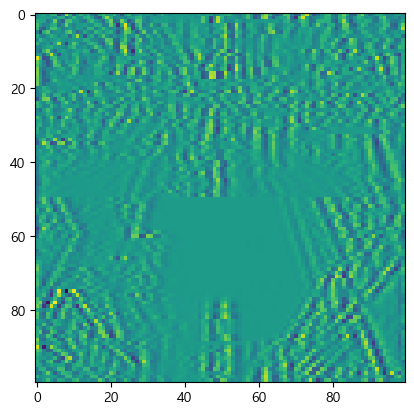

In [6]:
plt.imshow(broken_image.view(100,100))  # 이미지 출력

In [7]:
def distance_loss(hypothesis, broken_image):     # 함수 정의
    return torch.dist(hypothesis, broken_image) # 결과 반환

In [8]:
random_tensor = torch.randn(10000, dtype = torch.float) # 변수 설정

In [9]:
lr = 0.8 # 학습률 설정
for i in range(0,20000): # 반복문 수행
    random_tensor.requires_grad_(True) # 코드 실행
    hypothesis = weird_function(random_tensor) # 변수 설정
    loss = distance_loss(hypothesis, broken_image) # 변수 설정
    loss.backward() # 역전파 수행
    with torch.no_grad(): # 코드 실행
        random_tensor = random_tensor - lr*random_tensor.grad # 변수 설정
    if i % 1000 == 0: # 조건문 수행
        print('Loss at {} = {}'.format(i, loss.item())) # 결과 출력

Loss at 0 = 12.339202880859375
Loss at 1000 = 1.1690067052841187
Loss at 2000 = 0.5637571811676025
Loss at 3000 = 0.3817088305950165
Loss at 4000 = 0.2973407506942749
Loss at 5000 = 0.24726593494415283
Loss at 6000 = 0.2119472473859787
Loss at 7000 = 0.1841392070055008
Loss at 8000 = 0.16067391633987427
Loss at 9000 = 0.13994766771793365
Loss at 10000 = 0.12106049060821533
Loss at 11000 = 0.10346958041191101
Loss at 12000 = 0.08682892471551895
Loss at 13000 = 0.07090747356414795
Loss at 14000 = 0.05554483085870743
Loss at 15000 = 0.040626902133226395
Loss at 16000 = 0.026072697713971138
Loss at 17000 = 0.021159464493393898
Loss at 18000 = 0.021165907382965088
Loss at 19000 = 0.02116713486611843


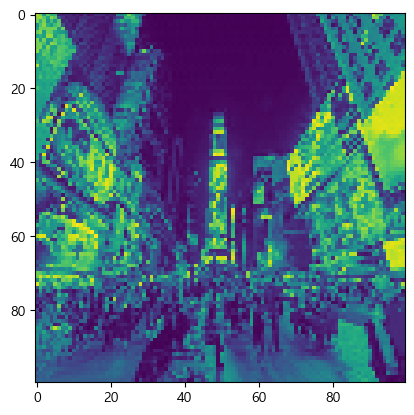

In [10]:
plt.imshow(random_tensor.view(100,100).data) # 이미지 출력